# finra-sensor-array 00 · Short interest and short sale volume

FINRA publishes two free datasets: **short interest** (shares sold short and still open on each
settlement date, twice a month, exchange-listed and OTC since 2017-12-29) and **daily short sale
volume** (the short part of each day's off-exchange volume, since 2009-08-03). This package stores
both as Parquet under `~/market_data/finra`, keyed by FINRA's own symbols, and this notebook
stays within it: no prices, no market caps (those joins are vinculum's).

1. what is stored
2. one name: GameStop, 2019-2021
3. the publication lag, and why it matters
4. symbols
5. the market: most shorted, total short interest over time
6. daily short sale volume

In [1]:
import matplotlib.pyplot as plt
import polars as pl
from finra_sensor_array import FinraStore, finra_symbols
from subspace_probe import human_bytes, style, timed

style()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(190)
finra = FinraStore()
status = finra.status()
pl.DataFrame([{"dataset": k, **{kk: (human_bytes(vv) if kk == "bytes" else vv) for kk, vv in v.items()}}
              for k, v in status.items() if isinstance(v, dict)])

dataset,days,first,last,rows,bytes
str,i64,str,str,i64,str
"""short_interest""",212,"""2017-12-29""","""2026-10-15""",4016870,"""97.8 MB"""
"""short_volume""",4341,"""2009-08-03""","""2026-11-03""",47942750,"""460.6 MB"""


## 1 · What is stored

Coverage by year: settlement dates and symbols for short interest, days and symbols for short
volume. The 2017 start of short interest is FINRA's consolidated feed; the short-volume files go
back to 2009 but gain symbols as reporting venues were added.

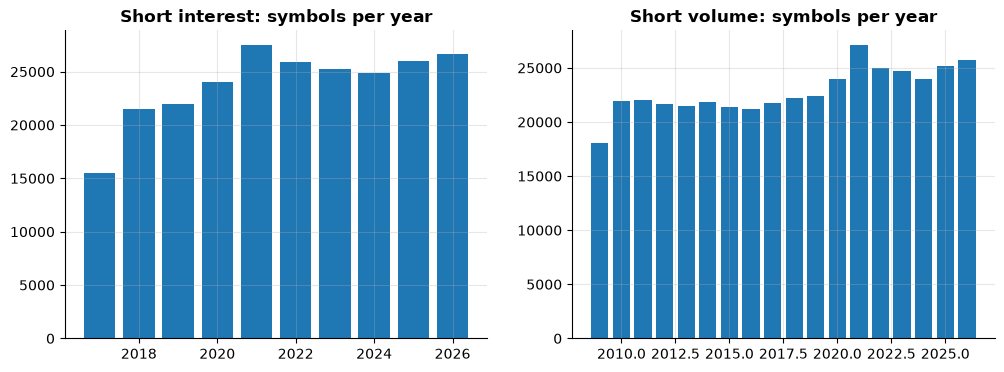

year,settlement_dates,symbols,rows
i32,u32,u32,u32
2017,1,15495,15495
2018,24,21484,375548
2019,24,21982,385795
2020,24,24053,414562
2021,24,27496,478429
2022,24,25948,496296
2023,24,25224,470207
2024,24,24864,468759
2025,24,26046,493428


In [2]:
si_years = (finra.scan("short_interest").group_by(pl.col("settlement_date").dt.year().alias("year"))
            .agg(pl.col("settlement_date").n_unique().alias("settlement_dates"), pl.col("symbol").n_unique().alias("symbols"),
                 pl.len().alias("rows")).sort("year").collect())
sv_years = (finra.scan("short_volume").group_by(pl.col("date").dt.year().alias("year"))
            .agg(pl.col("date").n_unique().alias("days"), pl.col("symbol").n_unique().alias("symbols"), pl.len().alias("rows"))
            .sort("year").collect())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(si_years["year"], si_years["symbols"])
axes[0].set_title("Short interest: symbols per year")
axes[1].bar(sv_years["year"], sv_years["symbols"])
axes[1].set_title("Short volume: symbols per year")
plt.show()
si_years

## 2 · One name: GameStop, 2019-2021

Short interest in shares and FINRA's days-to-cover (short interest / average daily volume).
Short interest peaked above 60 million shares, more than the float, before the January 2021
squeeze; days to cover collapsed as volume exploded. (Prices are not this package's business:
the same episode against the share price is in `vinculum/03_float_and_short.ipynb`.)

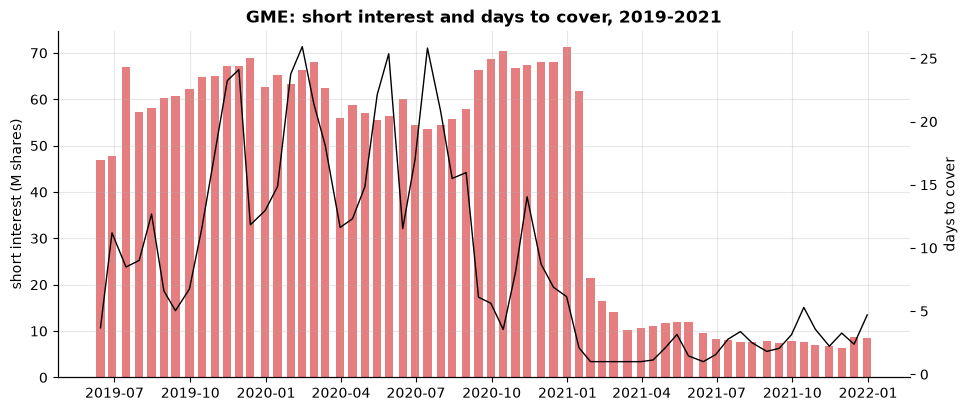

settlement_date,published_date,symbol,market,short_interest,previous_short_interest,change_pct,avg_daily_volume,days_to_cover
date,date,str,str,i64,i64,f64,i64,f64
2021-01-15,2021-01-27,"""GME""","""NYSE""",61782730,71196206,-13.22,29385884,2.1
2021-01-29,2021-02-09,"""GME""","""NYSE""",21409004,61782730,-65.35,96789540,1.0
2021-02-12,2021-02-24,"""GME""","""NYSE""",16468038,21409004,-23.08,40407815,1.0
2021-02-26,2021-03-09,"""GME""","""NYSE""",14200138,16468038,-13.77,35190707,1.0
2021-03-15,2021-03-24,"""GME""","""NYSE""",10187324,14200138,-28.26,35871397,1.0
2021-03-31,2021-04-12,"""GME""","""NYSE""",10696160,10187324,4.99,21048359,1.0


In [3]:
gme = finra.short_interest("GME", start="2019-06-01", end="2021-12-31")
fig, ax = plt.subplots()
ax.bar(gme["settlement_date"].to_list(), gme["short_interest"] / 1e6, width=10, color="tab:red", alpha=0.6)
ax.set_ylabel("short interest (M shares)")
ax2 = ax.twinx()
ax2.plot(gme["settlement_date"].to_list(), gme["days_to_cover"].to_list(), color="black", lw=1)
ax2.set_ylabel("days to cover")
ax2.grid(False)
ax.set_title("GME: short interest and days to cover, 2019-2021")
plt.show()
gme.filter(pl.col("settlement_date").dt.year() == 2021).head(6).select(
    "settlement_date", "published_date", "symbol", "market", "short_interest", "previous_short_interest", "change_pct", "avg_daily_volume", "days_to_cover")

## 3 · The publication lag, and why it matters

FINRA publishes a settlement date's short interest **seven business days later**. Every row
carries both dates. A point-in-time study must use `published_date`: on 2021-01-20 the 2021-01-15
settlement was not public yet.

In [4]:
lag = (finra.scan("short_interest").select("settlement_date", "published_date").unique()
       .with_columns((pl.col("published_date") - pl.col("settlement_date")).dt.total_days().alias("calendar_days"))
       .group_by("calendar_days").len().sort("calendar_days").collect())
print(lag)
by_settlement = finra.short_interest("GME", start="2021-01-15", end="2021-01-20", date_by="settlement")
by_published = finra.short_interest("GME", start="2021-01-15", end="2021-01-20", date_by="published")
print(f"window 2021-01-15..20 by settlement date: {by_settlement.height} row(s); by published date: {by_published.height} row(s)")
by_settlement.select("settlement_date", "published_date", "short_interest")

shape: (5, 2)
┌───────────────┬─────┐
│ calendar_days ┆ len │
│ ---           ┆ --- │
│ i64           ┆ u32 │
╞═══════════════╪═════╡
│ 9             ┆ 61  │
│ 10            ┆ 15  │
│ 11            ┆ 82  │
│ 12            ┆ 53  │
│ 13            ┆ 1   │
└───────────────┴─────┘
window 2021-01-15..20 by settlement date: 1 row(s); by published date: 0 row(s)


settlement_date,published_date,short_interest
date,date,i64
2021-01-15,2021-01-27,61782730


## 4 · Symbols

FINRA spells symbols its own way, and differently in the two datasets: short interest writes
share classes without a separator (`BRKB`) and preferreds with `PR`; the daily files write classes
with a slash (`BRK/B`). `finra_symbols` converts Massive-style tickers, and the store's queries
accept either spelling. Symbols are not identifiers: the same string can change hands, so joins
to other data go through the security master (vinculum does that).

In [5]:
tickers = ["BRK.B", "ABRpD", "AAPL", "NTGr"]
print(pl.DataFrame({"ticker": tickers, "short_interest": finra_symbols(tickers, "short_interest"),
                    "short_volume": finra_symbols(tickers, "short_volume")}))
print(finra.short_interest("BRK.B", start="2026-09-01").select("settlement_date", "symbol", "issue_name", "short_interest").tail(2))
print(finra.short_volume("BRK.B", start="2026-10-27").select("date", "symbol", "short_volume", "total_volume", "source").tail(2))

shape: (4, 3)
┌────────┬────────────────┬──────────────┐
│ ticker ┆ short_interest ┆ short_volume │
│ ---    ┆ ---            ┆ ---          │
│ str    ┆ str            ┆ str          │
╞════════╪════════════════╪══════════════╡
│ BRK.B  ┆ BRKB           ┆ BRK/B        │
│ ABRpD  ┆ ABRPRD         ┆ ABRpD        │
│ AAPL   ┆ AAPL           ┆ AAPL         │
│ NTGr   ┆ NTGr           ┆ NTGr         │
└────────┴────────────────┴──────────────┘
shape: (2, 4)
┌─────────────────┬────────┬────────────────────────────┬────────────────┐
│ settlement_date ┆ symbol ┆ issue_name                 ┆ short_interest │
│ ---             ┆ ---    ┆ ---                        ┆ ---            │
│ date            ┆ str    ┆ str                        ┆ i64            │
╞═════════════════╪════════╪════════════════════════════╪════════════════╡
│ 2026-09-30      ┆ BRKB   ┆ BERKSHIRE HATHAWAY Class B ┆ 12370081       │
│ 2026-10-15      ┆ BRKB   ┆ BERKSHIRE HATHAWAY Class B ┆ 13769255       │
└────────────────

## 5 · The market

The most shorted names on the latest settlement date by days to cover (among names with at
least a million shares short), and total short interest across the exchange-listed market over
time.

In [6]:
si = finra.scan("short_interest")
last = si.select(pl.col("settlement_date").max()).collect().item()
most = (si.filter((pl.col("settlement_date") == last) & (pl.col("short_interest") > 1e6)).collect()
        .sort("days_to_cover", descending=True).head(15)
        .select("symbol", "issue_name", "market", "short_interest", "avg_daily_volume", "days_to_cover"))
print(f"settlement {last}")
most

settlement 2026-10-15


symbol,issue_name,market,short_interest,avg_daily_volume,days_to_cover
str,str,str,i64,i64,f64
"""AACAF""","""AAC Technologies Holdings Inc""","""OTC""",4700836,0,999.99
"""ADDTF""","""ADDTECH AB SHARE AK B Ordinary""","""OTC""",1904173,0,999.99
"""AEGOF""","""Aegon Ltd Ordinary Shares""","""OTC""",6181474,8,999.99
"""AEMMF""","""A2A SpA Ordinary Shares""","""OTC""",15399457,0,999.99
"""AEOJF""","""Aeon Financial Services Co Ltd""","""OTC""",1892646,0,999.99
"""AGLNF""","""AGL Energy Ltd Ordinary Shares""","""OTC""",3524586,524,999.99
"""AHCHF""","""Anhui Conch Cement Shares -H-O""","""OTC""",11963372,96,999.99
"""AHEXF""","""Adecco Group AG Ordinary Share""","""OTC""",1798755,243,999.99
"""AHODF""","""Koninklijke Ahold Delhaize N V""","""OTC""",9809959,3728,999.99


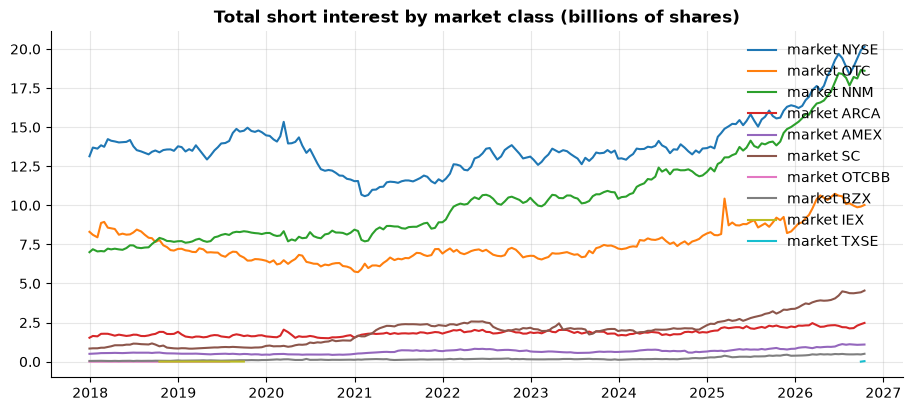

In [7]:
total = (si.group_by("settlement_date", "market").agg((pl.col("short_interest").sum() / 1e9).alias("bn_shares"),
                                                     pl.len().alias("symbols"))
         .sort("settlement_date").collect())
fig, ax = plt.subplots()
for (m,), g in total.group_by("market", maintain_order=True):
    ax.plot(g["settlement_date"], g["bn_shares"], label=f"market {m}")
ax.set_title("Total short interest by market class (billions of shares)")
ax.legend()
plt.show()

## 6 · Daily short sale volume

The short part of each day's **off-exchange** volume (trades reported to the TRFs and the ADF,
plus the OTC reporting facility for unlisted names). Market makers sell short routinely to fill
buy orders, so ratios of 40-60% are normal and are *not* short interest. Before 2018-08 the
facility files are summed (`source = TRF+ADF`); from then on FINRA's consolidated NMS file is used
(`CNMS`); OTC rows are `ORF`.

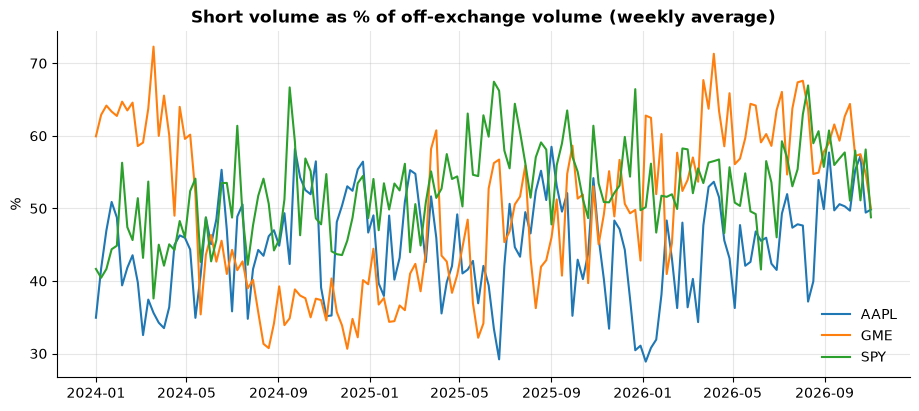

In [8]:
sv = (finra.short_volume(["SPY", "AAPL", "GME"], start="2024-01-01")
      .with_columns((pl.col("short_volume") / pl.col("total_volume") * 100).alias("short_volume_ratio")))
weekly = sv.group_by("symbol", pl.col("date").dt.truncate("1w").alias("week")).agg(pl.col("short_volume_ratio").mean()).sort("symbol", "week")
fig, ax = plt.subplots()
for (t,), g in weekly.group_by("symbol", maintain_order=True):
    ax.plot(g["week"].to_list(), g["short_volume_ratio"].to_list(), label=t)
ax.set_title("Short volume as % of off-exchange volume (weekly average)")
ax.set_ylabel("%")
ax.legend()
plt.show()

In [9]:
with timed("source by year over the whole history"):
    src = (finra.scan("short_volume").group_by(pl.col("date").dt.year().alias("year"), "source").len()
           .collect().pivot(on="source", index="year", values="len").sort("year").fill_null(0))
src

source by year over the whole history: 0.11 s


year,ORF,TRF+ADF,CNMS
i32,u32,u32,u32
2009,227699,701176,0
2010,572101,1647394,0
2011,584638,1627554,0
2012,515036,1597510,0
2013,561203,1632738,0
2014,636645,1803356,0
2015,568897,1838385,0
2016,555960,1864139,0
2017,646198,1911487,0


## Takeaways
- Short interest is point in time by `published_date` (settlement + 7 business days), never by
  settlement date.
- Short volume is posted the same evening and is usable from the next trading day; its ratio
  measures market-maker activity as much as bearish positioning.
- FINRA symbols differ between the two datasets and from Massive's; convert with
  `finra_symbols`, and identify companies through the security master, not the symbol.
- Short interest as a share of market cap or float, per security, is `Vinculum.short_interest()`.